Usando algún modelo basado en transformers, generemos una serie de tiempo aleatoria, con ruido y trae de predecir su comportamiento, por ejemplo con Chronos:

In [2]:
pip install -q chronos-forecasting

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.45.1 requires protobuf<7,>=3.20, but you have protobuf 7.35.1 which is incompatible.


In [7]:
import torch
print("CUDA disponible:", torch.cuda.is_available())

CUDA disponible: False


In [12]:
pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

Looking in indexes: https://download.pytorch.org/whl/cu121Note: you may need to restart the kernel to use updated packages.



In [10]:
torch

<module 'torch' from 'c:\\Users\\jtjua\\anaconda3\\Lib\\site-packages\\torch\\__init__.py'>

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

MAE Chronos (mediana): 1.771
MAE baseline estacional: 2.151
Cobertura del intervalo 10-90%: 67% (ideal ≈ 80%)


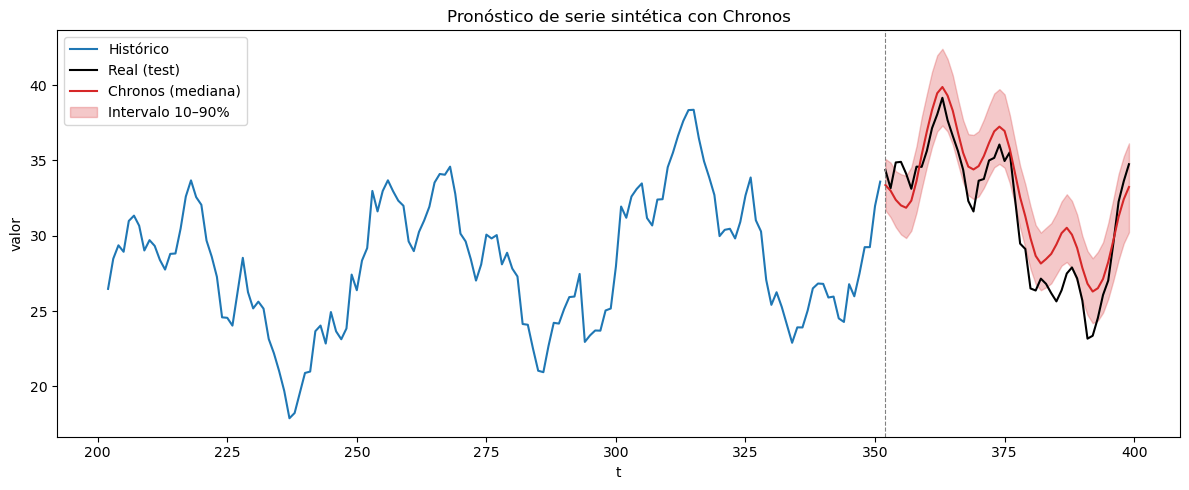

In [16]:
"""
Serie de tiempo sintética con ruido + pronóstico con Chronos (transformer pre-entrenado).

Instalación:
    pip install chronos-forecasting matplotlib numpy torch

Uso:
    python chronos_forecast.py
"""

import numpy as np
import torch
import matplotlib.pyplot as plt
from chronos import BaseChronosPipeline

# ---------------------------------------------------------------------------
# 1. Generar la serie aleatoria
# ---------------------------------------------------------------------------
rng = np.random.default_rng(seed=42)

N = 400            # puntos totales
H = 48             # horizonte de predicción (puntos a predecir)
t = np.arange(N)

trend = 0.03 * t                                   # tendencia lineal suave
seasonal = 5.0 * np.sin(2 * np.pi * t / 50) \
         + 2.0 * np.sin(2 * np.pi * t / 12)         # dos estacionalidades

# Ruido autocorrelacionado (AR(1)) + ruido blanco
ar = np.zeros(N)
for i in range(1, N):
    ar[i] = 0.7 * ar[i - 1] + rng.normal(0, 0.8)
noise = ar + rng.normal(0, 0.5, N)

series = 20 + trend + seasonal + noise

train, test = series[:-H], series[-H:]

# ---------------------------------------------------------------------------
# 2. Cargar Chronos y predecir
# ---------------------------------------------------------------------------
# Alternativas: "amazon/chronos-t5-small", "amazon/chronos-t5-base",
#               "amazon/chronos-bolt-small" (más rápido)
pipeline = BaseChronosPipeline.from_pretrained(
    "amazon/chronos-bolt-small",
    device_map="cuda" if torch.cuda.is_available() else "cpu",
    torch_dtype=torch.float32,
)

context = torch.tensor(train, dtype=torch.float32)
quantiles, mean = pipeline.predict_quantiles(
    context,
    prediction_length=H,
    quantile_levels=[0.1, 0.5, 0.9],
)
q10, q50, q90 = (quantiles[0, :, i].numpy() for i in range(3))

# ---------------------------------------------------------------------------
# 3. Evaluar contra un baseline ingenuo estacional
# ---------------------------------------------------------------------------
season = 50
naive = train[-season:][:H]                       # repite el último ciclo

mae_chronos = np.mean(np.abs(test - q50))
mae_naive = np.mean(np.abs(test - naive))
coverage = np.mean((test >= q10) & (test <= q90))

print(f"MAE Chronos (mediana): {mae_chronos:.3f}")
print(f"MAE baseline estacional: {mae_naive:.3f}")
print(f"Cobertura del intervalo 10-90%: {coverage:.0%} (ideal ≈ 80%)")

# ---------------------------------------------------------------------------
# 4. Graficar
# ---------------------------------------------------------------------------
x_train = np.arange(len(train))
x_test = np.arange(len(train), N)

plt.figure(figsize=(12, 5))
plt.plot(x_train[-150:], train[-150:], label="Histórico", color="tab:blue")
plt.plot(x_test, test, label="Real (test)", color="black")
plt.plot(x_test, q50, label="Chronos (mediana)", color="tab:red")
plt.fill_between(x_test, q10, q90, color="tab:red", alpha=0.25,
                 label="Intervalo 10–90%")
plt.axvline(len(train), color="gray", linestyle="--", linewidth=0.8)
plt.title("Pronóstico de serie sintética con Chronos")
plt.xlabel("t")
plt.ylabel("valor")
plt.legend()
plt.tight_layout()
plt.savefig("chronos_forecast.png", dpi=150)
plt.show()

Lo mismo para serie ruidosa SNR = -9dB

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from types import SimpleNamespace

BOLT_LEVELS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]  # cuantiles de Chronos-Bolt


# ---------- 1. Serie no estacionaria con SNR fija ----------
def make_series(n, snr_db, rng):
    """Devuelve (señal limpia, ruidosa, std del ruido, SNR real en dB).
    SNR = P_señal / P_ruido, con P_señal = varianza de la señal limpia."""
    t = np.arange(n)
    trend = 0.02 * t + 4e-5 * t**2                      # media variable
    level_shift = np.where(t >= n // 2, 4.0, 0.0)       # escalón a mitad de la serie
    random_walk = np.cumsum(rng.normal(0, 0.15, n))     # raíz unitaria
    f0, f1 = 1 / 60, 1 / 12                             # chirp: frecuencia y amplitud crecientes
    phase = 2 * np.pi * (f0 * t + 0.5 * (f1 - f0) * t**2 / n)
    chirp = 3.0 * (1 + t / n) * np.sin(phase)
    clean = 20 + trend + level_shift + random_walk + chirp

    noise_std = np.sqrt(np.var(clean) / 10 ** (snr_db / 10))
    noise = rng.normal(0, noise_std, n)
    snr_real = 10 * np.log10(np.var(clean) / np.var(noise))
    return clean, clean + noise, noise_std, snr_real


# ---------- 2. Modelo y pronóstico ----------
_PIPES = {}  # caché para no recargar el modelo en cada ejecución

def load_pipeline(model, device, dtype):
    import torch
    from chronos import BaseChronosPipeline, ChronosPipeline
    if device == "auto":
        device = "cuda" if torch.cuda.is_available() else "cpu"
    key = (model, device, dtype)
    if key not in _PIPES:
        pipe = BaseChronosPipeline.from_pretrained(
            model, device_map=device, torch_dtype=getattr(torch, dtype))
        _PIPES[key] = (pipe, isinstance(pipe, ChronosPipeline))  # True = familia T5
    return _PIPES[key]


def run_forecast(pipe, is_t5, context, horizon, a):
    """Devuelve (lo, med, hi, nube) con nube de forma (K, horizonte)."""
    import torch
    ctx = torch.tensor(context, dtype=torch.float32)
    if is_t5:
        torch.manual_seed(a.seed)
        out = pipe.predict(ctx, horizon, num_samples=a.num_samples,
                           temperature=a.temperature, top_k=a.top_k, top_p=a.top_p,
                           limit_prediction_length=False)
        cloud = out[0].float().numpy()                   # (num_samples, horizonte)
        lo, med, hi = np.quantile(cloud, [a.q_low, 0.5, a.q_high], axis=0)
        return lo, med, hi, cloud
    # Chronos-Bolt: predice 9 cuantiles fijos (0.1 ... 0.9); temperature/top_k/top_p no aplican
    q, _ = pipe.predict_quantiles(ctx, prediction_length=horizon, quantile_levels=BOLT_LEVELS)
    q = q[0].float().numpy()                             # (horizonte, 9)
    i_lo = int(np.argmin(np.abs(np.array(BOLT_LEVELS) - a.q_low)))
    i_hi = int(np.argmin(np.abs(np.array(BOLT_LEVELS) - a.q_high)))
    print(f"Chronos-Bolt: intervalo usado = [{BOLT_LEVELS[i_lo]}, {BOLT_LEVELS[i_hi]}] (solo múltiplos de 0.1)")
    return q[:, i_lo], q[:, 4], q[:, i_hi], q.T


# ---------- 3. Métricas ----------
def report(name, pred, noisy_test, clean_test):
    mae_n = np.mean(np.abs(noisy_test - pred))
    mae_c = np.mean(np.abs(clean_test - pred))
    rmse_c = np.sqrt(np.mean((clean_test - pred) ** 2))
    print(f"{name:<26} MAE vs ruidoso={mae_n:7.3f} | MAE vs limpia={mae_c:7.3f} | RMSE vs limpia={rmse_c:7.3f}")


# ---------- 4. Gráfica ----------
def plot_results(clean, noisy, horizon, lo, med, hi, cloud, a, snr_real):
    n = len(noisy); split = n - horizon
    t = np.arange(n); tt = t[split:]
    start = max(0, split - a.history)
    yerr = [np.clip(med - lo, 0, None), np.clip(hi - med, 0, None)]
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [3, 1.2]})

    ax.plot(t[start:split], noisy[start:split], color="tab:blue", lw=0.8, alpha=0.6, label="Observado (ruidoso)")
    ax.plot(t[start:], clean[start:], color="green", ls="--", lw=1.5, label="Señal limpia (verdad)")
    ax.scatter(tt, noisy[split:], color="black", s=14, zorder=3, label="Test (ruidoso)")
    if a.plot in ("scatter", "both"):
        ax.scatter(np.tile(tt, cloud.shape[0]), cloud.ravel(), s=6, color="tab:red", alpha=0.15,
                   label="Muestras / cuantiles del modelo")
    if a.plot in ("errorbar", "both"):
        ax.errorbar(tt, med, yerr=yerr, fmt="o-", color="tab:red", ms=3, lw=1, capsize=2, elinewidth=1,
                    label=f"Chronos: mediana ± [{a.q_low:.0%}, {a.q_high:.0%}]")
    else:
        ax.plot(tt, med, color="tab:red", lw=1.5, label="Chronos (mediana)")
    ax.axvline(split, color="gray", ls="--", lw=0.8)
    ax.set_title(f"Serie no estacionaria, SNR = {snr_real:.1f} dB  |  {a.model}")
    ax.set_xlabel("t"); ax.set_ylabel("valor"); ax.legend(loc="upper left", fontsize=8)

    ax2.errorbar(clean[split:], med, yerr=yerr, fmt="o", ms=3, color="tab:red", alpha=0.7,
                 elinewidth=0.8, capsize=2)
    lim = [min(clean[split:].min(), lo.min()), max(clean[split:].max(), hi.max())]
    ax2.plot(lim, lim, "k--", lw=1, label="y = x")
    ax2.set_xlabel("Señal limpia (real)"); ax2.set_ylabel("Estimación de Chronos")
    ax2.set_title("Estimado vs real"); ax2.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

In [ ]:
import traceback
import ipywidgets as widgets
from IPython.display import display

st = {"description_width": "120px"}
lay = widgets.Layout(width="330px")
def S(cls, desc, **kw):
    return cls(description=desc, style=st, layout=lay, **kw)

W = {
    # serie
    "n":        S(widgets.IntSlider, "Puntos (n)", value=400, min=100, max=2000, step=50),
    "horizon":  S(widgets.IntSlider, "Horizonte", value=48, min=8, max=256, step=8),
    "snr_db":   S(widgets.FloatSlider, "SNR (dB)", value=-9.0, min=-20, max=20, step=0.5),
    "seed":     S(widgets.IntText, "Semilla", value=42),
    # modelo
    "model":    S(widgets.Dropdown, "Modelo", value="amazon/chronos-bolt-small", options=[
                    "amazon/chronos-bolt-tiny", "amazon/chronos-bolt-mini",
                    "amazon/chronos-bolt-small", "amazon/chronos-bolt-base",
                    "amazon/chronos-t5-tiny", "amazon/chronos-t5-mini", "amazon/chronos-t5-small",
                    "amazon/chronos-t5-base", "amazon/chronos-t5-large"]),
    "context_length": S(widgets.IntSlider, "Contexto (0 = todo)", value=0, min=0, max=1024, step=16),
    "q_low":    S(widgets.FloatSlider, "Cuantil inferior", value=0.1, min=0.05, max=0.45, step=0.05),
    "q_high":   S(widgets.FloatSlider, "Cuantil superior", value=0.9, min=0.55, max=0.95, step=0.05),
    "num_samples": S(widgets.IntSlider, "num_samples (T5)", value=100, min=10, max=500, step=10),
    "temperature": S(widgets.FloatSlider, "temperature (T5)", value=1.0, min=0.1, max=2.0, step=0.1),
    "top_k":    S(widgets.IntSlider, "top_k (T5)", value=50, min=1, max=200, step=1),
    "top_p":    S(widgets.FloatSlider, "top_p (T5)", value=1.0, min=0.1, max=1.0, step=0.05),
    "device":   S(widgets.Dropdown, "Dispositivo", value="auto", options=["auto", "cpu", "cuda", "mps"]),
    "dtype":    S(widgets.Dropdown, "dtype", value="float32", options=["float32", "bfloat16", "float16"]),
    # gráfica
    "plot":     S(widgets.Dropdown, "Gráfica", value="both", options=["errorbar", "scatter", "both"]),
    "history":  S(widgets.IntSlider, "Histórico a mostrar", value=150, min=30, max=500, step=10),
}

btn = widgets.Button(description="Ejecutar", button_style="primary", icon="play")
out = widgets.Output()


def on_run(_):
    btn.disabled = True
    out.clear_output(wait=True)
    with out:
        try:
            a = SimpleNamespace(**{k: w.value for k, w in W.items()})
            H = a.horizon
            rng = np.random.default_rng(a.seed)
            clean, noisy, noise_std, snr_real = make_series(a.n, a.snr_db, rng)
            train, noisy_test, clean_test = noisy[:-H], noisy[-H:], clean[-H:]
            context = train[-a.context_length:] if a.context_length > 0 else train
            print(f"SNR pedida = {a.snr_db:.1f} dB | real = {snr_real:.2f} dB | "
                  f"std señal = {np.std(clean):.2f} | std ruido = {noise_std:.2f}")

            print(f"Cargando {a.model} ...")
            pipe, is_t5 = load_pipeline(a.model, a.device, a.dtype)
            lo, med, hi, cloud = run_forecast(pipe, is_t5, context, H, a)

            baseline = np.full(H, train[-24:].mean())   # media de los últimos 24 puntos
            print()
            report("Chronos (mediana)", med, noisy_test, clean_test)
            report("Baseline (media 24 últ.)", baseline, noisy_test, clean_test)
            print(f"Cobertura sobre test ruidoso:  {np.mean((noisy_test >= lo) & (noisy_test <= hi)):.0%}")
            print(f"Cobertura sobre señal limpia: {np.mean((clean_test >= lo) & (clean_test <= hi)):.0%}")
            plot_results(clean, noisy, H, lo, med, hi, cloud, a, snr_real)
        except Exception:
            traceback.print_exc()
        finally:
            btn.disabled = False

btn.on_click(on_run)

def box(title, keys):
    return widgets.VBox([widgets.HTML(f"<b>{title}</b>")] + [W[k] for k in keys])

panel = widgets.VBox([
    widgets.HBox([
        box("Serie", ["n", "horizon", "snr_db", "seed"]),
        box("Modelo", ["model", "context_length", "q_low", "q_high", "num_samples",
                       "temperature", "top_k", "top_p", "device", "dtype"]),
        box("Gráfica", ["plot", "history"]),
    ]),
    btn,
    out,
])
display(panel)